# BioTwin Singapore — defensible EDA for horticultural waste planning

**BPS5231 | Revised after interim feedback | 12 November 2026**

**Narrow scope:** Singapore feedstock estimation and **one** conversion pathway: pyrolysis to biochar. This is an exploratory spatial analysis, *not* an operational waste forecast, certified carbon registry, NSGA-II solver, or demonstrated global platform. An independent Streamlit prototype and deterministic planning engine accompany this notebook.

**Completed in this notebook:** national historical waste and current-use diagnostics, tree and land-cover proxy preparation, allocation to 55 planning areas, 2,000 proxy-weight sensitivity runs, and grouped validation of a Random Forest for managed-tree biomass proxy.

**Not validated:** true planning-area waste, operational collection flows, land parcels/road routing, eligible credited removals, commercial economics. A high internal rank stability is not real-world accuracy. A Random Forest R² of 0.364 refers to log managed-tree biomass proxy per grid cell, *not* monthly horticultural waste or worldwide transfer.

**Workflow:** run this notebook top to bottom with internet/data access; its final export cell can populate `BioTwin_Prototype/data/planning_area_estimates.csv` for the web application. Without exported data, the companion app uses the five region summaries embedded from this notebook's saved output and labels their limitations.

| Research step | Output | Status |
|---|---|---|
| National series and current waste use | 2000–2025, separate wood/horticultural caveat | Descriptive; checked against NEA |
| Weather association | national annual exploratory correlations | Inconclusive, not evidence of true causes |
| Spatial proxies | managed tree, height/girth assumptions, WorldCover, reserves | EDA implemented; no field calibration |
| Spatial allocations | 55 planning areas and regional aggregates | Model estimate only; real regional validation pending |
| Proxy weight uncertainty | 2,000 Dirichlet weight scenarios | Internal sensitivity only |
| Machine learning | grouped cross-validation, `log1p` managed-tree biomass target | Modest model; NOT waste forecasting |
| Pyrolysis, sites, carbon and economics | separate Streamlit scenario model | Illustrative, assumptions documented; no formal validation |

**Recalculation correction:** The original scenario cell accidentally used 2017–2025 (9 years) despite saying “last 10 years,” because its window ended in 2026. It now selects the last 10 actually observed years, 2016–2025. Based on the embedded national series, P10 ≈ 231,000 t, median ≈ 317,000 t and P90 ≈ 412,000 t. Rerun the notebook to refresh its saved figures/CSVs.


## 0 · Setup

In [ ]:

import sys, importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
if IN_COLAB:
    need = {"geopandas": "geopandas", "rasterio": "rasterio", "pyproj": "pyproj", "shapely": "shapely", "sklearn": "scikit-learn"}
    missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
    if missing:
        pkgs = " ".join(missing)
        %pip install -q {pkgs}
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/BPS5231_horticultural_waste")
    else:
        PROJECT_DIR = Path("/content/BPS5231_horticultural_waste")   # wiped when the runtime resets
else:
    PROJECT_DIR = Path.cwd()

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Running in {'Google Colab' if IN_COLAB else 'a local Jupyter kernel'}; project folder: {PROJECT_DIR}")

In [ ]:
import io, json, math, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140, "display.max_columns", 30)

# ---- paths ------------------------------------------------------------------
ROOT = PROJECT_DIR
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
for p in (RAW, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

# ---- analysis settings (tune these pls) -----------------------------------------
START_YEAR, END_YEAR = 2000, 2026
REFERENCE_YEAR = 2025
SCENARIO_WINDOW = 10
HEAVY_RAIN_MM = 50
STRONG_GUST_KMH = 40
WEATHER_SOURCE = "auto"
MSS_STATIONS = {"S24": "Changi"} # add stations, e.g. {"S24": "Changi", "S50": "Clementi"}
WOOD_DENSITY = 0.60              # g/cm3; a constant multiplier, so it does not change any planning area's SHARE
GIRTH_MIDPOINT_M = {"XS": 0.25, "S": 0.8, "M": 1.3, "L": 1.9}  # class midpoints; L (>1.5 m) is open-ended: 1.9 is an assumption
N_WEIGHT_SAMPLES = 2000          # Monte Carlo
SEED = 42

GRID_PIXELS = 25
SOURCES = {}
NOTES = []

In [6]:
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "Mozilla/5.0 (academic EDA notebook; horticultural waste study)"

def cached_download(url, dest, params=None, timeout=120):
    """Download url to dest once; later calls return the cached file."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    r = SESSION.get(url, params=params, timeout=timeout)
    r.raise_for_status()
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_bytes(r.content)
    return dest

DATAGOV = "https://api-open.data.gov.sg/v1/public/api/datasets/{}"

def datagov_download(dataset_id, dest, max_polls=8):
    """Download a data.gov.sg dataset (CSV or GeoJSON) via the v1 open API."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    url = None
    for attempt in range(max_polls):
        r = SESSION.get(DATAGOV.format(dataset_id) + "/poll-download", timeout=30)
        payload = r.json() if r.ok else {}
        url = (payload.get("data") or {}).get("url")
        if url:
            break
        if attempt == 0:   # file not prepared yet: ask the API to prepare it
            SESSION.get(DATAGOV.format(dataset_id) + "/initiate-download", timeout=30)
        time.sleep(3)
    if not url:
        raise RuntimeError(f"data.gov.sg did not return a download URL for {dataset_id}")
    return cached_download(url, dest)

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())

In [7]:


C = ["#2a78d6", "#eb6834", "#1baf7a"]                         # blue, orange, aqua
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE, NEUTRAL = "#fcfcfb", "#f0efec"
GREEN_RAMP = ["#ddf6e0", "#b1e3b7", "#80cd8b", "#56b368", "#38964d", "#2a783c", "#1d5b2b"]
SEQ = LinearSegmentedColormap.from_list("seq_green", GREEN_RAMP)
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", NEUTRAL, "#f0a3a2", "#c73736"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": BASE,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "axes.axisbelow": True,
})

EVENTS = {2019: "Biomass fuel counted\nas recycling from 2019", 2020: "COVID-19"}

def mark_events(ax, label=True):
    for i, (yr, txt) in enumerate(sorted(EVENTS.items())):
        ax.axvline(yr, color=BASE, lw=1, ls="--", zorder=0)
        if label:   # alternate sides so adjacent labels never collide
            left = i % 2 == 0
            ax.annotate(txt, (yr, 0), xycoords=("data", "axes fraction"), xytext=(-4 if left else 4, 4),
                        textcoords="offset points", va="bottom", ha="right" if left else "left", fontsize=8, color=INK2)

def legend_above(ax, ncol=3):
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=ncol, fontsize=9, handlelength=1.6)

## 0b · Data sources

| Dataset | Publisher | Used for | Fallback if unreachable |
|---|---|---|---|
| [Waste Management and Overall Recycling Rates, Annual](https://data.gov.sg/datasets/d_daf568968ab40dc81e7b08887a83c8fa/view) | SingStat / MSE / NEA via data.gov.sg | Horticultural and wood waste, 2000–2025 | Embedded copy, cross-checked against [NEA Waste and Recycling Statistics 2015–2025](https://www.nea.gov.sg/docs/default-source/default-document-library/waste-and-recycling-statistics-2015-to-2025.pdf) |
| [NEA Waste and Recycling Statistics 2015–2025](https://www.nea.gov.sg/docs/default-source/default-document-library/waste-and-recycling-statistics-2015-to-2025.pdf) (footnotes) | NEA | Tonnes of wood + horticultural waste used as fuel, 2017–2025 | Embedded (PDF footnotes) |
| [MSS historical daily records](http://www.weather.gov.sg/climate-historical-daily/) | Meteorological Service Singapore | Daily rainfall, wind, temperature | [Open-Meteo archive](https://open-meteo.com/en/docs/historical-weather-api) (ERA5) |
| [Master Plan 2019 Subzone Boundary](https://data.gov.sg/datasets/d_8594ae9ff96d0c708bc2af633048edfb/view) | URA via data.gov.sg | 55 planning areas and 5 regions | MP2014 boundaries, [GitHub yinshanyang/singapore](https://github.com/yinshanyang/singapore) |
| [Nature Reserves Gazette](https://data.gov.sg/datasets/d_dfd037f5064cb2e2b2e358ceeccb4af7/view) | NParks via data.gov.sg | Separating managed from protected greenery | Skipped |
| [Trees.sg data](https://github.com/cheeaun/sgtreesdata) (community copy, Oct 2021) | NParks (© NParks) | 696,228 recorded managed trees: location, species, girth and height class | None |
| [ESA WorldCover 2021](https://esa-worldcover.org) | European Space Agency | 10 m land cover (tree, shrub, grass, built…) | Skipped; manual download instructions printed |

## 1 · National horticultural waste series

**Definition break:** from 2019, recycled wood and horticultural waste includes material burned as fuel in biomass power plants, so recycling rates before and after 2019 are not directly comparable. NEA reports **wood waste** (pallets, crates, furniture, construction timber) separately from **horticultural waste** (tree trunks, branches, plant parts and trimmings); this project's feedstock is horticultural waste, and wood waste is shown for context.

In [8]:
WASTE_DATASET_ID = "d_daf568968ab40dc81e7b08887a83c8fa"

_YEARS = list(range(2000, 2026))
SNAPSHOT = pd.DataFrame({
    "generated": [131000, 281000, 417000, 305000, 227000, 200000, 231000, 225000, 229000, 238000, 270000, 274000, 248000,
                  253000, 278000, 362000, 321000, 328000, 521000, 400000, 313000, 332000, 221000, 256000, 265000, 232000],
    "recycled":  [55000, 89000, 118000, 119000, 128000, 101000, 87000, 91000, 96000, 94000, 190000, 177000, 108000,
                  121000, 163000, 237000, 209000, 221000, 428000, 293000, 249000, 277000, 188000, 218000, 225000, 176000],
    "disposed":  [75000, 192000, 300000, 185000, 99000, 99000, 144000, 134000, 133000, 145000, 80000, 97000, 140000,
                  132000, 115000, 125000, 112000, 108000, 93000, 107000, 64000, 55000, 32000, 38000, 40000, 55000],
}, index=pd.Index(_YEARS, name="year"), dtype=float)

SNAPSHOT["recycling_rate_pct"] = 100 * SNAPSHOT.recycled / SNAPSHOT.generated
# Wood waste, 2015-2025, from NEA Waste and Recycling Statistics 2015-2025 (tonnes)
WOOD_SNAPSHOT = pd.DataFrame({
    "generated": [371000, 531000, 424000, 320000, 438000, 304000, 310000, 419000, 447000, 410000, 428000],
    "recycled":  [294000, 412000, 327000, 227000, 289000, 195000, 234000, 298000, 299000, 250000, 258000],
    "disposed":  [77000, 119000, 97000, 93000, 149000, 109000, 76000, 121000, 149000, 160000, 170000],
}, index=pd.Index(range(2015, 2026), name="year"), dtype=float)
WOOD_SNAPSHOT["recycling_rate_pct"] = 100 * WOOD_SNAPSHOT.recycled / WOOD_SNAPSHOT.generated

def _to_tonnes(s):
    m = s.max(skipna=True)
    return s * 1e6 if m < 10 else s * 1e3 if m < 5000 else s   # million / thousand tonnes -> tonnes

def _classify_rows(sub, snap):
    """Map each data row of one waste type to a measure, by label keyword, else by matching the snapshot."""
    out = {}
    for rid, g in sub.groupby("row"):
        label, s = g.label.iloc[0].lower(), g.set_index("year").value
        hit = next((m for k, m in [("rate", "recycling_rate_pct"), ("generat", "generated"),
                                   ("recycl", "recycled"), ("dispos", "disposed")] if k in label), None)
        if hit or snap is None:
            out[rid] = hit
            continue
        best, err = None, np.inf
        for meas in ["generated", "recycled", "disposed", "recycling_rate_pct"]:
            cand = s if meas == "recycling_rate_pct" else _to_tonnes(s)
            ref = snap[meas].dropna()
            common = ref.index.intersection(cand.dropna().index)
            if len(common) >= 3:
                e = float(np.mean(np.abs(cand[common] - ref[common]) / ref[common]))
                if e < err:
                    best, err = meas, e
        out[rid] = best if err < 0.15 else None
    return out

def load_waste_from_datagov():
    df = pd.read_csv(datagov_download(WASTE_DATASET_ID, RAW / "waste_management_recycling_annual.csv"))
    year_cols = [c for c in df.columns if re.fullmatch(r"\s*\d{4}\s*", str(c))]
    df = df.reset_index().rename(columns={"index": "row", df.columns[0]: "label"})
    long = df.melt(id_vars=["row", "label"], value_vars=year_cols, var_name="year", value_name="value")
    long["year"] = long.year.astype(str).str.strip().astype(int)
    long["value"] = pd.to_numeric(long.value, errors="coerce")
    long["label"] = long.label.astype(str)

    out, horti_order = {}, None
    for wtype, pattern in [("horticultural", r"horticult"), ("wood", r"\bwood")]:
        sub = long[long.label.str.contains(pattern, case=False, regex=True)]
        if sub.empty:
            continue
        cls = _classify_rows(sub, SNAPSHOT if wtype == "horticultural" else WOOD_SNAPSHOT)
        if wtype == "horticultural":
            horti_order = [cls[r] for r in sorted(cls)]
        elif horti_order and all(v is None for v in cls.values()) and len(cls) == len(horti_order):
            cls = dict(zip(sorted(cls), horti_order))   # unlabeled rows: same order as horticultural block
        wide = {}
        for rid, meas in cls.items():
            if meas and meas not in wide:
                s = sub[sub.row == rid].set_index("year").value
                wide[meas] = s if meas == "recycling_rate_pct" else _to_tonnes(s)
        if wide:
            out[wtype] = pd.DataFrame(wide).sort_index().rename_axis("year")
    return out

try:
    api = load_waste_from_datagov()
    horti = api["horticultural"]
    if "generated" not in horti:
        raise ValueError("could not identify the 'generated' row")
    missing = [c for c in ["recycled", "disposed"] if c not in horti]
    horti = horti.combine_first(SNAPSHOT[["generated", "recycled", "disposed"]])
    wood = WOOD_SNAPSHOT.copy()
    if "wood" in api and "generated" in api["wood"]:
        live = api["wood"][[c for c in ("generated", "recycled", "disposed") if c in api["wood"]]]
        dev = (live.generated.reindex(WOOD_SNAPSHOT.index) / WOOD_SNAPSHOT.generated - 1).abs().max()
        if dev < 0.05:   # use the live wood rows only if they match the NEA PDF
            wood = live.combine_first(WOOD_SNAPSHOT)
        else:
            NOTES.append(f"Wood rows from data.gov.sg differ from the NEA PDF by up to {dev:.0%}; NEA PDF values used.")
    SOURCES["National waste series"] = "data.gov.sg API (live)" + (f"; {missing} filled from snapshot" if missing else "")
    common = horti.generated.dropna().index.intersection(SNAPSHOT.generated.index)
    max_dev = (horti.generated[common] / SNAPSHOT.generated[common] - 1).abs().max()
    print(f"Cross-check vs snapshot: max deviation in 'generated' = {max_dev:.1%} over {len(common)} years")
except Exception as e:
    horti = SNAPSHOT[["generated", "recycled", "disposed"]].copy()
    wood = WOOD_SNAPSHOT.copy()
    SOURCES["National waste series"] = f"embedded snapshot (API unavailable: {type(e).__name__})"

horti = horti.loc[START_YEAR:END_YEAR]
horti["recycling_rate_pct"] = 100 * horti.recycled / horti.generated
print("Source:", SOURCES["National waste series"])
horti.style.format("{:,.0f}", na_rep="-")

Cross-check vs snapshot: max deviation in 'generated' = 0.0% over 26 years
Source: data.gov.sg API (live)


,disposed,generated,recycled,recycling_rate_pct
year,,,,
2000,"75,000","131,000","55,000",42
2001,"192,000","281,000","89,000",32
2002,"300,000","417,000","118,000",28
2003,"185,000","305,000","119,000",39
2004,"99,000","227,000","128,000",56
2005,"99,000","200,000","101,000",50
2006,"144,000","231,000","87,000",38
2007,"134,000","225,000","91,000",40
2008,"133,000","229,000","96,000",42


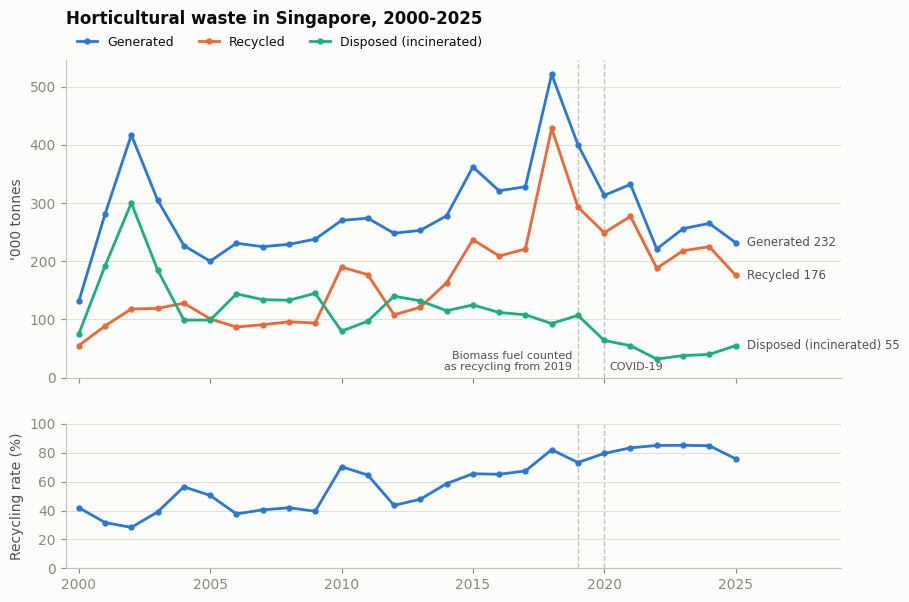

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
series = [("generated", C[0], "Generated"), ("recycled", C[1], "Recycled"), ("disposed", C[2], "Disposed (incinerated)")]
ends = []
for col, color, label in series:
    s = horti[col].dropna() / 1e3
    ax1.plot(s.index, s.values, color=color, marker="o", ms=3.5, label=label)
    ends.append([s.iloc[-1], s.index[-1], f"{label} {s.iloc[-1]:,.0f}"])
ax1.set_ylabel("'000 tonnes")
ax1.set_ylim(0, None)
gap = 0.07 * ax1.get_ylim()[1]
ends.sort()
for i in range(1, len(ends)):
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + gap)
for y, x, txt in ends:
    ax1.annotate(txt, (x, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK2)
legend_above(ax1)
ax1.set_title("Horticultural waste in Singapore, 2000-2025", pad=26)
mark_events(ax1)
r = horti.recycling_rate_pct.dropna()
ax2.plot(r.index, r.values, color=C[0], marker="o", ms=3.5)
ax2.set_ylim(0, 100)
ax2.set_ylabel("Recycling rate (%)")
mark_events(ax2, label=False)
ax2.set_xlim(horti.index.min() - 0.5, horti.index.max() + 4)
savefig(fig, "01_national_series")
plt.show()

### 1a · What "recycled" means, and wood waste for context

NEA footnotes give the tonnes of wood **and** horticultural waste (combined) sent to facilities to be burned as fuel. Dividing by the combined recycled tonnes shows how much of "recycling" is burning for energy. NEA does not split this between the two streams.

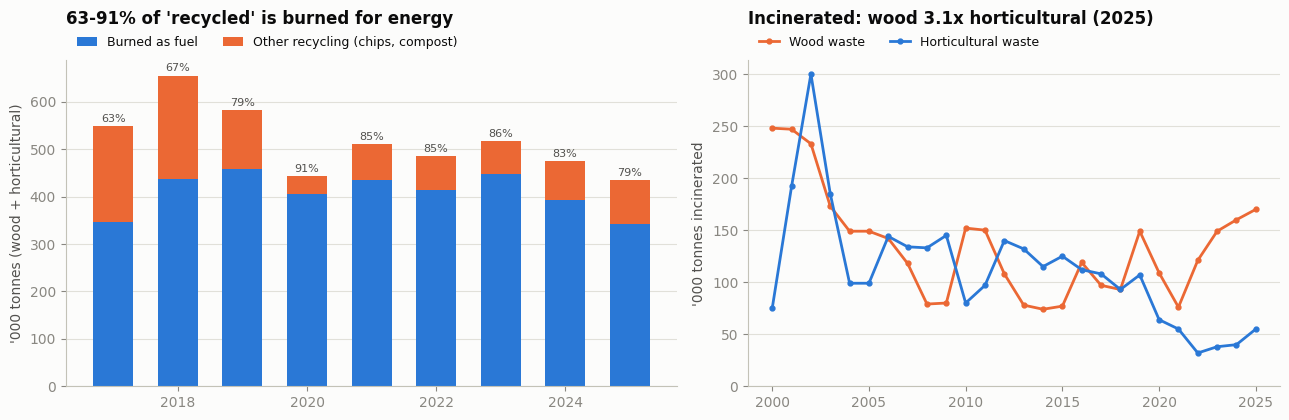

,fuel_t,recycled_combined_t,other_recycling_t,fuel_share_pct
2017,347000,548000.0,201000.0,63.0
2018,438000,655000.0,217000.0,67.0
2019,458000,582000.0,124000.0,79.0
2020,406000,444000.0,38000.0,91.0
2021,435000,511000.0,76000.0,85.0
2022,414000,486000.0,72000.0,85.0
2023,447000,517000.0,70000.0,86.0
2024,392000,475000.0,83000.0,83.0
2025,342000,434000.0,92000.0,79.0


In [10]:
FUEL_T = pd.Series({2017: 347000, 2018: 438000, 2019: 458000, 2020: 406000, 2021: 435000,
                    2022: 414000, 2023: 447000, 2024: 392000, 2025: 342000}, name="fuel_t")   # NEA statistics PDF footnotes
SOURCES["Fuel tonnage"] = "NEA Waste and Recycling Statistics 2015-2025, footnotes (wood + horticultural combined)"
combined = pd.DataFrame({"horticultural": horti.recycled, "wood": wood.recycled}).loc[FUEL_T.index]
fuel = pd.DataFrame({"fuel_t": FUEL_T, "recycled_combined_t": combined.sum(axis=1)})
fuel["other_recycling_t"] = fuel.recycled_combined_t - fuel.fuel_t
fuel["fuel_share_pct"] = 100 * fuel.fuel_t / fuel.recycled_combined_t
fuel.to_csv(PROC / "fuel_share.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
x = fuel.index
a1.bar(x, fuel.fuel_t / 1e3, color=C[0], width=0.62, label="Burned as fuel")
a1.bar(x, fuel.other_recycling_t / 1e3, bottom=fuel.fuel_t / 1e3, color=C[1], width=0.62, label="Other recycling (chips, compost)")
for yr, r in fuel.iterrows():
    a1.annotate(f"{r.fuel_share_pct:.0f}%", (yr, r.recycled_combined_t / 1e3), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=INK2)
a1.set_ylabel("'000 tonnes (wood + horticultural)")
lo_s, hi_s = fuel.fuel_share_pct.min(), fuel.fuel_share_pct.max()
a1.set_title(f"{lo_s:.0f}-{hi_s:.0f}% of 'recycled' is burned for energy", pad=26)
legend_above(a1, 2)

w = wood.disposed.dropna() / 1e3
h = horti.disposed.loc[w.index.min():] / 1e3
a2.plot(w.index, w.values, color=C[1], marker="o", ms=3.5, label="Wood waste")
a2.plot(h.index, h.values, color=C[0], marker="o", ms=3.5, label="Horticultural waste")
a2.set_ylim(0, None)
a2.set_ylabel("'000 tonnes incinerated")
ratio = w.iloc[-1] / h.loc[w.index[-1]]
a2.set_title(f"Incinerated: wood {ratio:.1f}x horticultural ({w.index[-1]})", pad=26)
legend_above(a2, 2)
fig.tight_layout()
savefig(fig, "01a_fuel_share_and_wood")
plt.show()
wood.to_csv(PROC / "wood_waste_annual.csv")
fuel.round(0)

### 1b · Anomalous years and trend

A year is flagged when its year-on-year change has a robust z-score |z| > 2. Explanations are filled only where a source states one; the rest are listed in §6 for you to source.

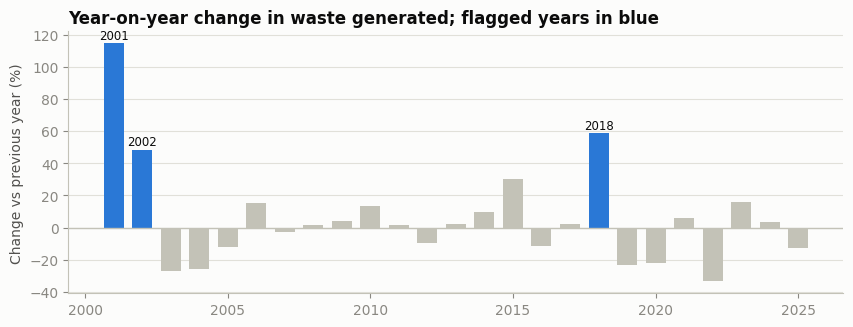

,generated_t,yoy_pct,robust_z,explanation
year,,,,
2001,281000.0,114.5,5.63,Not explained
2002,417000.0,48.4,2.32,Not explained
2018,521000.0,58.8,2.84,Not explained


,n,kendall_tau,p_value,theil_sen_t_per_yr,slope_95ci
2000-2025,26,0.24,0.086,3111,"[-571, 7,714]"
2017-2026,9,-0.56,0.045,-23667,"[-46,000, -5,000]"


In [11]:
yoy = horti.generated.pct_change() * 100
mad = stats.median_abs_deviation(yoy.dropna(), scale="normal")
rz = (yoy - yoy.median()) / mad
flag = rz.abs() > 2
KNOWN = {2019: "Definition change: biomass fuel counted as recycling (NEA footnote)",
         2020: "COVID-19 year (NEA footnote on overall waste)"}
anomalies = pd.DataFrame({"generated_t": horti.generated, "yoy_pct": yoy.round(1), "robust_z": rz.round(2)})[flag]
anomalies["explanation"] = [KNOWN.get(y, "Not explained") for y in anomalies.index]

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(yoy.index, yoy.values, color=np.where(flag, C[0], BASE), width=0.7)
for yr in yoy.index[flag]:
    ax.annotate(str(yr), (yr, yoy[yr]), xytext=(0, 3 if yoy[yr] > 0 else -11), textcoords="offset points",
                ha="center", fontsize=8.5, color=INK)
ax.axhline(0, color=BASE, lw=1)
ax.set_ylabel("Change vs previous year (%)")
ax.set_title("Year-on-year change in waste generated; flagged years in blue")
savefig(fig, "01b_yoy_anomalies")
plt.show()
display(anomalies)

TREND = {}
for label, s in [("2000-2025", horti.generated.dropna()), (f"{END_YEAR - SCENARIO_WINDOW + 1}-{END_YEAR}", horti.generated.loc[END_YEAR - SCENARIO_WINDOW + 1:].dropna())]:
    tau, p = stats.kendalltau(s.index, s.values)
    slope, intercept, lo_s, hi_s = stats.theilslopes(s.values, s.index)
    TREND[label] = dict(n=len(s), kendall_tau=round(tau, 2), p_value=round(p, 3), theil_sen_t_per_yr=round(slope), slope_95ci=f"[{lo_s:,.0f}, {hi_s:,.0f}]")
TREND = pd.DataFrame(TREND).T
TREND

In [ ]:
window = horti.generated.loc[:REFERENCE_YEAR].dropna().tail(SCENARIO_WINDOW)
scenarios = pd.DataFrame({"scenario": ["low (P10)", "typical (median)", "high (P90)"],  # historical range, last 10 years
                          "generated_t": window.quantile([0.1, 0.5, 0.9]).round(-3).values})
scenarios["basis"] = f"{window.index.min()}-{window.index.max()} (n={len(window)})"
scenarios.to_csv(PROC / "generation_scenarios.csv", index=False)
horti.to_csv(PROC / "horticultural_waste_annual.csv")
scenarios

## 2 · Weather vs waste (short)

**Finding to test:** annual weather does not explain annual waste. Waste is one national figure per year (~26 points), while storms act over days. Weather source: MSS station records when reachable, otherwise the Open-Meteo ERA5 archive (which understates rainfall extremes).

In [ ]:
MSS_URL = "http://www.weather.gov.sg/files/dailydata/DAILYDATA_{st}_{ym}.csv"

def parse_mss(path, station):
    raw = Path(path).read_bytes()
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            text = raw.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    df = pd.read_csv(io.StringIO(text))
    df.columns = [c.strip() for c in df.columns]
    pick = lambda key: next((c for c in df.columns if key in c.lower()), None)
    out = pd.DataFrame({
        "date": pd.to_datetime(dict(year=df[pick("year")], month=df[pick("month")], day=df[pick("day")]), errors="coerce"),
        "rain_mm": pd.to_numeric(df[pick("rainfall total")], errors="coerce"),
        "gust_kmh": pd.to_numeric(df[pick("max wind")], errors="coerce") if pick("max wind") else np.nan,
        "tmean_c": pd.to_numeric(df[pick("mean temp")], errors="coerce") if pick("mean temp") else np.nan,
    })
    out["station"] = station
    return out.dropna(subset=["date"])

def load_mss():
    frames, failed = [], 0
    for st, name in MSS_STATIONS.items():
        for y in range(START_YEAR, END_YEAR + 1):
            for m in range(1, 13):
                ym = f"{y}{m:02d}"
                try:
                    p = cached_download(MSS_URL.format(st=st, ym=ym), RAW / "mss" / f"{st}_{ym}.csv", timeout=30)
                    frames.append(parse_mss(p, name))
                except Exception:
                    failed += 1
                    if not frames and failed >= 3:   # the site is unreachable: stop early
                        raise RuntimeError("MSS daily records not reachable")
        print(f"  {name}: loaded")
    if failed:
        NOTES.append(f"MSS: {failed} station-months could not be downloaded.")
    d = pd.concat(frames)
    return d.groupby("date").agg(rain_mm=("rain_mm", "mean"), gust_kmh=("gust_kmh", "max"), tmean_c=("tmean_c", "mean")).reset_index()

def load_open_meteo():
    p = RAW / f"open_meteo_sg_{START_YEAR}_{END_YEAR}.json"
    if not p.exists():
        r = SESSION.get("https://archive-api.open-meteo.com/v1/archive", timeout=120, params={
            "latitude": 1.35, "longitude": 103.82, "timezone": "Asia/Singapore",
            "start_date": f"{START_YEAR}-01-01", "end_date": f"{END_YEAR}-12-31",
            "daily": "precipitation_sum,wind_gusts_10m_max,temperature_2m_mean"})
        r.raise_for_status()
        p.write_text(r.text)
    d = json.loads(p.read_text())["daily"]
    return pd.DataFrame({"date": pd.to_datetime(d["time"]), "rain_mm": d["precipitation_sum"],
                         "gust_kmh": d["wind_gusts_10m_max"], "tmean_c": d["temperature_2m_mean"]})

daily = None
if WEATHER_SOURCE in ("auto", "mss"):
    try:
        daily = load_mss()
        SOURCES["Weather"] = f"MSS daily records, stations {list(MSS_STATIONS.values())}"
    except Exception as e:
        print(f"MSS unavailable ({e}).")
        if WEATHER_SOURCE == "mss":
            raise
if daily is None:
    daily = load_open_meteo()
    SOURCES["Weather"] = "Open-Meteo archive (ERA5 reanalysis, 1.35N 103.82E); extremes understated"
daily = daily[(daily.date.dt.year >= START_YEAR) & (daily.date.dt.year <= END_YEAR)]
print("Weather source:", SOURCES["Weather"], "|", daily.date.min().date(), "to", daily.date.max().date())

  Changi: loaded
Weather source: MSS daily records, stations ['Changi'] | 2000-01-01 to 2026-08-31


In [ ]:
def annual_weather(daily):
    d = daily.set_index("date")
    g = d.groupby(d.index.year)
    days_in_year = pd.Series({y: 366 if pd.Timestamp(y, 12, 31).dayofyear == 366 else 365 for y in g.groups})
    feat = pd.DataFrame({
        "coverage": g.rain_mm.count() / days_in_year,
        "rain_total_mm": g.rain_mm.sum(min_count=1),
        "heavy_rain_days": g.rain_mm.apply(lambda s: (s >= HEAVY_RAIN_MM).sum()),
        "max_daily_rain_mm": g.rain_mm.max(),
        "strong_wind_days": g.gust_kmh.apply(lambda s: (s >= STRONG_GUST_KMH).sum()),
        "max_gust_kmh": g.gust_kmh.max(),
        "mean_temp_c": g.tmean_c.mean(),
    }).rename_axis("year")
    dropped = feat.index[feat.coverage < 0.8].tolist()
    if dropped:
        NOTES.append(f"Weather years dropped for <80% daily coverage: {dropped}")
    return feat[feat.coverage >= 0.8]

weather = annual_weather(daily)
weather.to_csv(PROC / "weather_annual.csv")
weather.round(1)

,coverage,rain_total_mm,heavy_rain_days,max_daily_rain_mm,strong_wind_days,max_gust_kmh,mean_temp_c
year,,,,,,,
2000,1.0,2370.5,7,127.6,56,67.7,27.5
2001,1.0,2783.1,11,211.1,33,73.4,27.6
2002,1.0,1748.9,6,84.0,45,52.6,28.1
2003,1.0,2391.2,9,194.4,41,54.0,27.8
2004,1.0,2136.4,9,177.8,38,55.8,27.9
2005,1.0,1930.7,5,133.8,36,59.4,28.0
2006,1.0,2753.2,10,197.9,34,57.2,27.7
2007,1.0,2886.2,14,159.0,40,66.6,27.5
2008,1.0,2325.1,6,133.9,26,52.6,27.5


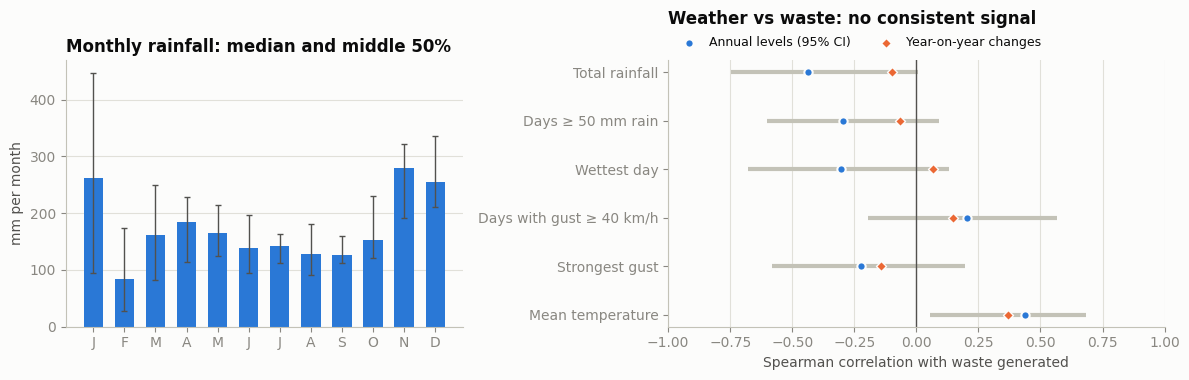

Features significant in BOTH levels and year-on-year changes, same sign: none


,n,rho,ci_low,ci_high,p,rho_year_on_year,p_year_on_year
feature,,,,,,,
Total rainfall,26,-0.44,-0.75,0.01,0.03,-0.10,0.64
Days ≥ 50 mm rain,26,-0.30,-0.60,0.09,0.14,-0.07,0.75
Wettest day,26,-0.30,-0.68,0.13,0.13,0.07,0.74
Days with gust ≥ 40 km/h,26,0.20,-0.20,0.57,0.32,0.15,0.48
Strongest gust,26,-0.22,-0.58,0.20,0.27,-0.14,0.49
Mean temperature,26,0.44,0.06,0.68,0.03,0.37,0.07


In [ ]:
FEATURES = {"rain_total_mm": "Total rainfall", "heavy_rain_days": f"Days ≥ {HEAVY_RAIN_MM} mm rain",
            "max_daily_rain_mm": "Wettest day", "strong_wind_days": f"Days with gust ≥ {STRONG_GUST_KMH} km/h",
            "max_gust_kmh": "Strongest gust", "mean_temp_c": "Mean temperature"}
merged = weather.join(horti.generated, how="inner").dropna(subset=["generated"])
rng = np.random.default_rng(SEED)
rows = []
for f, name in FEATURES.items():
    d = merged[[f, "generated"]].dropna()
    if len(d) < 6 or d[f].nunique() < 3:
        continue
    rho, p = stats.spearmanr(d[f], d.generated)
    dd = d.diff().dropna()
    rho_d, p_d = stats.spearmanr(dd[f], dd.generated)
    boots = [stats.spearmanr(*d.iloc[rng.integers(0, len(d), len(d))].T.values)[0] for _ in range(1000)]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    rows.append(dict(feature=name, n=len(d), rho=rho, ci_low=lo, ci_high=hi, p=p, rho_year_on_year=rho_d, p_year_on_year=p_d))
corr = pd.DataFrame(rows).set_index("feature")
consistent = corr[(corr.p < 0.05) & (corr.p_year_on_year < 0.05) & (np.sign(corr.rho) == np.sign(corr.rho_year_on_year))]

monthly = daily.set_index("date").rain_mm.resample("MS").sum(min_count=20).to_frame()
monthly["month"] = monthly.index.month
clim = monthly.groupby("month").rain_mm.quantile([0.25, 0.5, 0.75]).unstack()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.25]})
a1.bar(clim.index, clim[0.5], color=C[0], width=0.62)
a1.errorbar(clim.index, clim[0.5], yerr=[clim[0.5] - clim[0.25], clim[0.75] - clim[0.5]], fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
a1.set_xticks(range(1, 13), list("JFMAMJJASOND"))
a1.set_ylabel("mm per month")
a1.set_title("Monthly rainfall: median and middle 50%")

yy = np.arange(len(corr))[::-1]
a2.hlines(yy, corr.ci_low, corr.ci_high, color=BASE, lw=3)
a2.scatter(corr.rho, yy, color=C[0], s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5, label="Annual levels (95% CI)")
a2.scatter(corr.rho_year_on_year, yy, color=C[1], marker="D", s=26, zorder=3, edgecolor=SURFACE, linewidth=1, label="Year-on-year changes")
a2.axvline(0, color=INK2, lw=1)
a2.set_yticks(yy, corr.index)
a2.set_xlim(-1, 1)
a2.set_xlabel("Spearman correlation with waste generated")
a2.grid(axis="x"); a2.grid(axis="y", visible=False)
a2.set_title("Weather vs waste: no consistent signal", pad=26)
legend_above(a2, 2)
fig.tight_layout()
savefig(fig, "02_weather_vs_waste")
plt.show()
print("Features significant in BOTH levels and year-on-year changes, same sign:", list(consistent.index) or "none")
corr.round(2)

**Interpretation:** Annual weather correlations in this small national sample are weak or inconsistent. This does **not** establish the cause of annual variation. Maintenance schedules, land development, reporting boundaries and storms are *hypotheses requiring operator or municipal records*. We do not infer that maintenance is the “true driver,” nor claim monthly waste forecasts.

## 3 · Managed vegetation by planning area

| Layer | Source |
|---|---|
| Planning areas | URA Master Plan 2019 subzones (data.gov.sg), dissolved to 55 planning areas; fallback: MP2014 (GitHub `yinshanyang/singapore`) |
| Managed trees | NParks Trees.sg via [`cheeaun/sgtreesdata`](https://github.com/cheeaun/sgtreesdata), last updated Oct 2021 (© NParks) |
| Land cover | ESA WorldCover 2021, 10 m |
| Nature reserves | NParks Nature Reserves Gazette (data.gov.sg) |

**Biomass proxy:** Chave et al. (2014) allometry, AGB = 0.0673·(ρ·D²·H)^0.976, with D and H from the inventory's girth and height classes. It is a **relative** index for sharing out the national total; ρ is a constant and does not change any area's share.

In [ ]:
import geopandas as gpd
from shapely.geometry import box

SUBZONE_DATASET_ID = "d_8594ae9ff96d0c708bc2af633048edfb"       # URA MP2019 subzone boundary (no sea), GeoJSON
RESERVES_DATASET_ID = "d_dfd037f5064cb2e2b2e358ceeccb4af7"      # NParks nature reserves gazette
PA_FALLBACK_URL = "https://raw.githubusercontent.com/yinshanyang/singapore/master/maps/2-planning-area.geojson"
SVY21 = "EPSG:3414"

def _pa_name(row):
    for k in ("PLN_AREA_N", "pln_area_n", "PLANNING_AREA", "planning_area"):
        if k in row and pd.notna(row[k]):
            return str(row[k]).strip().upper()
    desc = str(row.get("Description", row.get("description", "")))
    m = re.search(r"PLN_AREA_N\s*</th>\s*<td>\s*([^<]+?)\s*</td>", desc, flags=re.I)
    return m.group(1).strip().upper() if m else None

def load_planning_areas():
    try:
        sz = gpd.read_file(datagov_download(SUBZONE_DATASET_ID, RAW / "mp2019_subzones.geojson"))
        sz["planning_area"] = sz.apply(_pa_name, axis=1)
        if sz.planning_area.isna().all():
            raise ValueError("planning-area names not found in subzone attributes")
        pa = sz.dropna(subset=["planning_area"]).dissolve("planning_area").reset_index()[["planning_area", "geometry"]]
        SOURCES["Planning areas"] = "URA Master Plan 2019 subzones (data.gov.sg), dissolved"
    except Exception as e:
        print(f"MP2019 boundaries unavailable ({type(e).__name__}); using MP2014 fallback.")
        pa = gpd.read_file(cached_download(PA_FALLBACK_URL, RAW / "mp2014_planning_areas.geojson"))
        pa = pa.rename(columns={"name": "planning_area"})[["planning_area", "geometry"]]
        pa["planning_area"] = pa.planning_area.str.upper()
        SOURCES["Planning areas"] = "URA Master Plan 2014 planning areas (GitHub yinshanyang/singapore)"
    pa = pa.set_crs(4326, allow_override=pa.crs is None).to_crs(SVY21)
    pa["geometry"] = pa.geometry.buffer(0)
    pa["area_km2"] = pa.area / 1e6
    return pa.sort_values("planning_area").reset_index(drop=True)

def load_reserves():
    try:
        nr = gpd.read_file(datagov_download(RESERVES_DATASET_ID, RAW / "nature_reserves.geojson"))
        SOURCES["Nature reserves"] = "NParks Nature Reserves Gazette (data.gov.sg)"
        return nr.to_crs(SVY21)[["geometry"]].assign(geometry=lambda g: g.geometry.buffer(0))
    except Exception as e:
        SOURCES["Nature reserves"] = f"not available ({type(e).__name__}); managed/unmanaged split skipped"
        return None

pa = load_planning_areas()
reserves = load_reserves()
if reserves is not None:
    inter = gpd.overlay(pa[["planning_area", "geometry"]], reserves, how="intersection", keep_geom_type=True)
    pa = pa.merge(inter.dissolve("planning_area").area.div(1e6).rename("reserve_km2"),
                  left_on="planning_area", right_index=True, how="left").fillna({"reserve_km2": 0})
    pa["reserve_share"] = (pa.reserve_km2 / pa.area_km2).clip(0, 1)
print(f"{len(pa)} planning areas | total {pa.area_km2.sum():,.0f} km² | source: {SOURCES['Planning areas']}")

55 planning areas | total 785 km² | source: URA Master Plan 2019 subzones (data.gov.sg), dissolved


In [ ]:
# Five URA planning regions: from the MP2019 subzone attributes when available, else MP2014 regions (GitHub)
REGION_FALLBACK_URL = "https://raw.githubusercontent.com/yinshanyang/singapore/master/maps/1-region.geojson"

def _region_name(row):
    for k in ("REGION_N", "region_n"):
        if k in row and pd.notna(row[k]):
            return str(row[k]).strip().upper()
    m = re.search(r"REGION_N\s*</th>\s*<td>\s*([^<]+?)\s*</td>", str(row.get("Description", "")), flags=re.I)
    return m.group(1).strip().upper() if m else None

regions = None
sz_file = RAW / "mp2019_subzones.geojson"
if sz_file.exists():
    sz = gpd.read_file(sz_file)
    sz["region"] = sz.apply(_region_name, axis=1)
    if sz.region.notna().any():
        regions = sz.dropna(subset=["region"]).dissolve("region").reset_index()[["region", "geometry"]]
        SOURCES["Regions"] = "URA Master Plan 2019 subzones (REGION_N), dissolved"
if regions is None:
    regions = gpd.read_file(cached_download(REGION_FALLBACK_URL, RAW / "mp2014_regions.geojson")).rename(columns={"name": "region"})
    regions["region"] = regions.region.str.upper()
    SOURCES["Regions"] = "URA Master Plan 2014 regions (GitHub yinshanyang/singapore)"
regions = regions.set_crs(4326, allow_override=regions.crs is None).to_crs(SVY21)
regions["geometry"] = regions.geometry.buffer(0)
regions["region"] = regions.region.str.replace(" REGION", "", regex=False).str.title()

pts = pa[["planning_area", "geometry"]].copy()
pts["geometry"] = pts.geometry.representative_point()
pa = pa.drop(columns="region", errors="ignore").merge(
    gpd.sjoin(pts, regions[["region", "geometry"]], predicate="within")[["planning_area", "region"]],
    on="planning_area", how="left")
print(pa.groupby("region").planning_area.count().rename("planning areas").to_string())
if pa.region.isna().any():
    NOTES.append(f"Planning areas without a region match: {sorted(pa.planning_area[pa.region.isna()])}")

region
Central       22
East           6
North          8
North-East     7
West          12


In [ ]:
TREES_URL = "https://raw.githubusercontent.com/cheeaun/sgtreesdata/main/data/trees.csv"
SPECIES_URL = "https://raw.githubusercontent.com/cheeaun/sgtreesdata/main/data/species.json"

trees = pd.read_csv(cached_download(TREES_URL, RAW / "trees.csv"))
species = json.loads(cached_download(SPECIES_URL, RAW / "species.json").read_text(encoding="utf-8"))
SOURCES["Managed trees"] = "NParks Trees.sg via GitHub cheeaun/sgtreesdata (© NParks)"


trees["girth_m"] = trees.girth_size.map(GIRTH_MIDPOINT_M)
trees["height_m"] = (trees.height_est.where(trees.height_est >= 3) - 1.5).clip(lower=1.5)
imp_g, imp_h = trees.girth_m.isna().mean(), trees.height_m.isna().mean()
trees["girth_m"] = trees.girth_m.fillna(trees.girth_m.median())
trees["height_m"] = trees.height_m.fillna(trees.groupby("girth_m").height_m.transform("median"))
NOTES.append(f"Trees: {imp_g:.2%} missing girth and {imp_h:.2%} missing height imputed (median / median-by-girth).")

d_cm = trees.girth_m * 100 / np.pi
trees["agb_kg"] = 0.0673 * (WOOD_DENSITY * d_cm**2 * trees.height_m) ** 0.976
trees["species"] = trees.species_id.map(lambda i: species.get(str(int(i)), {}).get("name") if pd.notna(i) else None)

tg = gpd.GeoDataFrame(trees[["species", "girth_size", "height_m", "agb_kg"]],
                      geometry=gpd.points_from_xy(trees.lng, trees.lat), crs=4326).to_crs(SVY21)
tg = gpd.sjoin(tg, pa[["planning_area", "geometry"]], how="left", predicate="within")
outside = tg.planning_area.isna().mean()
NOTES.append(f"Trees: {outside:.2%} of points fall outside planning-area polygons (coast/offshore) and are excluded.")
tg = tg.dropna(subset=["planning_area"])
print(f"{len(trees):,} trees loaded; {len(tg):,} matched to planning areas")

696,228 trees loaded; 695,912 matched to planning areas


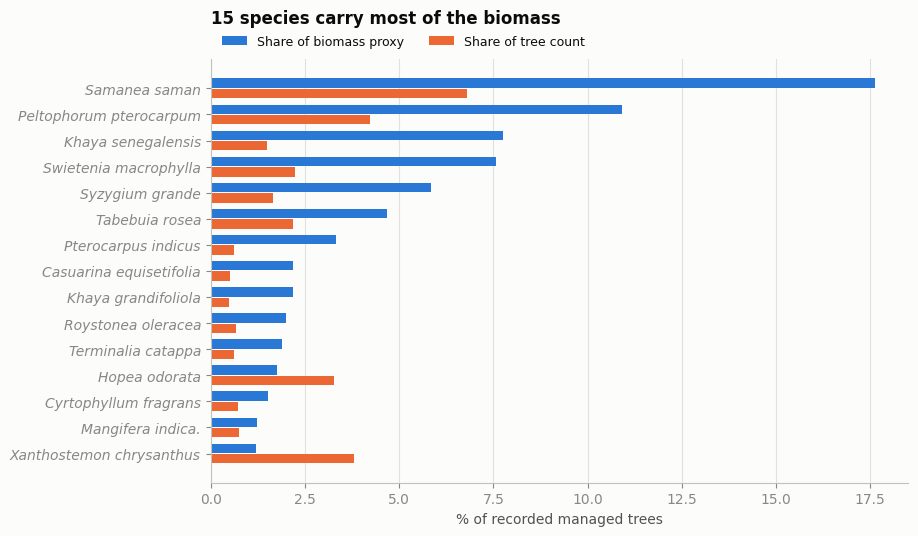

Top 15 species hold 72% of biomass proxy and 30% of trees.


In [ ]:
def shannon(s):
    p = s.value_counts(normalize=True)
    return float(-(p * np.log(p)).sum())

tree_stats = tg.groupby("planning_area").agg(
    n_trees=("agb_kg", "size"),
    agb_t=("agb_kg", lambda s: s.sum() / 1e3),
    mean_height_m=("height_m", "mean"),
    share_large_girth=("girth_size", lambda s: (s == "L").mean()),
    n_species=("species", "nunique"),
    shannon_species=("species", shannon),
)
pa = pa.drop(columns=tree_stats.columns, errors="ignore").merge(tree_stats, left_on="planning_area", right_index=True, how="left")
pa[["n_trees", "agb_t"]] = pa[["n_trees", "agb_t"]].fillna(0)
pa["trees_per_km2"] = pa.n_trees / pa.area_km2
pa["agb_t_per_km2"] = pa.agb_t / pa.area_km2

# National species profile: by count vs by biomass
sp = tg.groupby("species").agg(n=("agb_kg", "size"), agb=("agb_kg", "sum"))
sp["share_count"], sp["share_agb"] = sp.n / sp.n.sum(), sp.agb / sp.agb.sum()
top = sp.nlargest(15, "agb").sort_values("share_agb")

fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(top))
ax.barh(y + 0.2, top.share_agb * 100, height=0.36, color=C[0], label="Share of biomass proxy")
ax.barh(y - 0.2, top.share_count * 100, height=0.36, color=C[1], label="Share of tree count")
ax.set_yticks(y, top.index, fontstyle="italic")
ax.set_xlabel("% of recorded managed trees")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("15 species carry most of the biomass", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
savefig(fig, "03a_species_biomass_vs_count")
plt.show()
print(f"Top 15 species hold {top.share_agb.sum():.0%} of biomass proxy and {top.share_count.sum():.0%} of trees.")

In [ ]:
import rasterio
from rasterio import features
from rasterio.windows import from_bounds, Window

WC_URL = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E102_Map.tif"
WC_LOCAL = RAW / "worldcover_sg_2021.tif"
SG_BBOX = (103.55, 1.15, 104.10, 1.48)
WC_CLASSES = {10: "tree", 20: "shrub", 30: "grass", 40: "cropland", 50: "built", 60: "bare",
              80: "water", 90: "herb_wetland", 95: "mangrove"}
GREEN = [10, 20, 30, 90, 95]

def fetch_worldcover():
    if WC_LOCAL.exists():
        return WC_LOCAL
    with rasterio.Env(GDAL_HTTP_TIMEOUT="60", GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
        with rasterio.open("/vsicurl/" + WC_URL) as src:
            w = from_bounds(*SG_BBOX, transform=src.transform)
            w = Window(int(w.col_off), int(w.row_off), int(math.ceil(w.width)), int(math.ceil(w.height)))
            arr, tr = src.read(1, window=w), src.window_transform(w)
            prof = {"driver": "GTiff", "dtype": arr.dtype, "count": 1, "crs": src.crs, "transform": tr,
                    "height": arr.shape[0], "width": arr.shape[1], "compress": "deflate", "nodata": 0}
    with rasterio.open(WC_LOCAL, "w", **prof) as dst:
        dst.write(arr, 1)
    return WC_LOCAL

wc_ok = False
try:
    with rasterio.open(fetch_worldcover()) as src:
        lc, tr, wc_crs = src.read(1), src.transform, src.crs
    zones = features.rasterize(((g, i + 1) for i, g in enumerate(pa.to_crs(wc_crs).geometry)),
                               out_shape=lc.shape, transform=tr, fill=0, dtype="int32")
    in_res = np.zeros(lc.shape, bool)
    if reserves is not None:
        in_res = features.rasterize(((g, 1) for g in reserves.to_crs(wc_crs).geometry),
                                    out_shape=lc.shape, transform=tr, fill=0, dtype="uint8").astype(bool)
    valid = (zones > 0) & (lc > 0)
    nz = len(pa) + 1
    total = np.bincount(zones[valid], minlength=nz).astype(float)
    frac = {}
    for cls, name in WC_CLASSES.items():
        frac[name] = np.bincount(zones[valid & (lc == cls)], minlength=nz) / np.maximum(total, 1)
    green_mask = np.isin(lc, GREEN) & valid
    frac["green"] = np.bincount(zones[green_mask], minlength=nz) / np.maximum(total, 1)
    frac["green_managed"] = np.bincount(zones[green_mask & ~in_res], minlength=nz) / np.maximum(total, 1)
    for k in ["tree", "built", "green", "green_managed"]:
        pa[f"{k}_pct"] = 100 * frac[k][1:]
    pa["green_km2"] = pa.green_pct / 100 * pa.area_km2
    pa["green_managed_km2"] = pa.green_managed_pct / 100 * pa.area_km2
    SOURCES["Land cover"] = "ESA WorldCover 2021 v200 (10 m)"
    wc_ok = True
    print(f"WorldCover: national tree cover {100 * (lc[valid] == 10).mean():.1f}%, green {100 * green_mask.sum() / valid.sum():.1f}%")
except Exception as e:
    SOURCES["Land cover"] = f"not available ({type(e).__name__}); land-cover proxies skipped"
    print("WorldCover unavailable. To use it, download the N00E102 tile from https://esa-worldcover.org and "
          f"save a clip of Singapore as {WC_LOCAL}. Continuing with tree-inventory proxies only.")

WorldCover: national tree cover 32.8%, green 44.5%


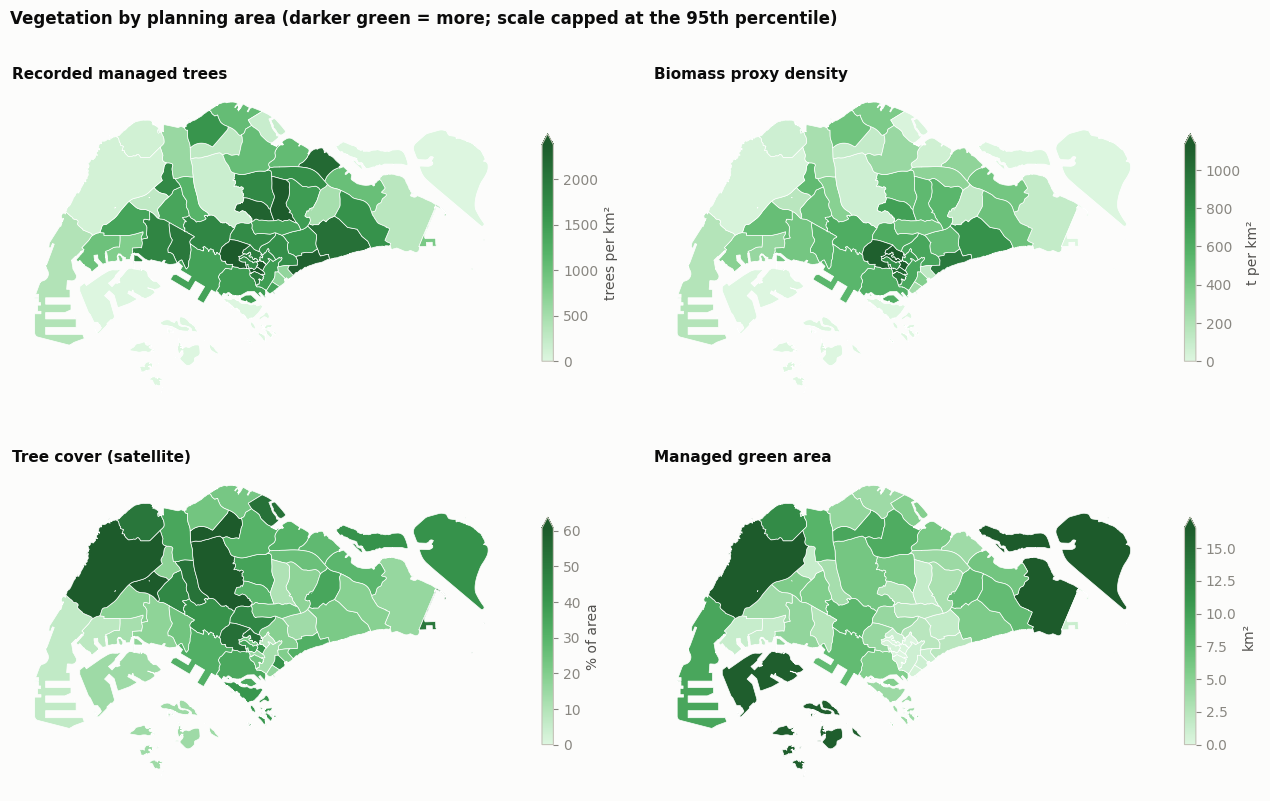

In [ ]:
def choropleth(ax, gdf, col, title, label, cap=95):
    vals = gdf[col]
    vmax = np.nanpercentile(vals, cap) if vals.notna().any() else 1
    gdf.plot(column=col, ax=ax, cmap=SEQ, vmin=0, vmax=vmax, edgecolor="white", linewidth=0.5,
             legend=True, legend_kwds={"shrink": 0.55, "label": label, "extend": "max" if cap < 100 else "neither"},
             missing_kwds={"color": NEUTRAL, "edgecolor": BASE, "hatch": "///", "label": "No data"})
    ax.set_axis_off()
    ax.set_title(title, fontsize=11)

panels = [("trees_per_km2", "Recorded managed trees", "trees per km²"),
          ("agb_t_per_km2", "Biomass proxy density", "t per km²")]
if wc_ok:
    panels += [("tree_pct", "Tree cover (satellite)", "% of area"),
               ("green_managed_km2", "Managed green area" if reserves is not None else "Green area", "km²")]
nrows = math.ceil(len(panels) / 2)
fig, axes = plt.subplots(nrows, 2, figsize=(13, 4.3 * nrows))
for ax, (col, title, label) in zip(np.atleast_1d(axes).flat, panels):
    choropleth(ax, pa, col, title, label)
fig.suptitle("Vegetation by planning area (darker green = more; scale capped at the 95th percentile)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "03b_vegetation_maps")
plt.show()

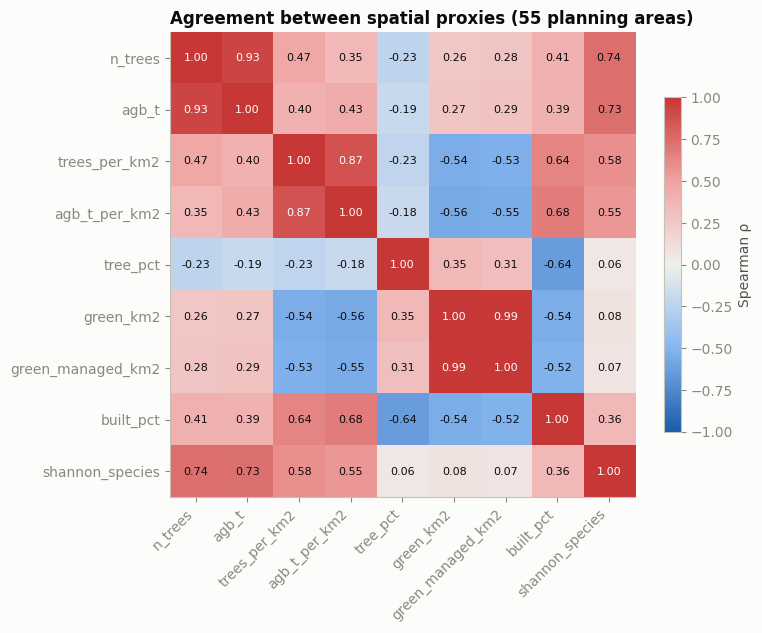

In [ ]:
# Do the proxies agree?
proxy_cols = [c for c in ["n_trees", "agb_t", "trees_per_km2", "agb_t_per_km2", "tree_pct", "green_km2",
                          "green_managed_km2", "built_pct", "shannon_species"] if c in pa]
cm = pa[proxy_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cm, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(proxy_cols)), proxy_cols, rotation=45, ha="right")
ax.set_yticks(range(len(proxy_cols)), proxy_cols)
ax.grid(False)
for i in range(len(proxy_cols)):
    for j in range(len(proxy_cols)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(cm.iloc[i, j]) > 0.75 else INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Agreement between spatial proxies (55 planning areas)")
savefig(fig, "03c_proxy_correlation")
plt.show()

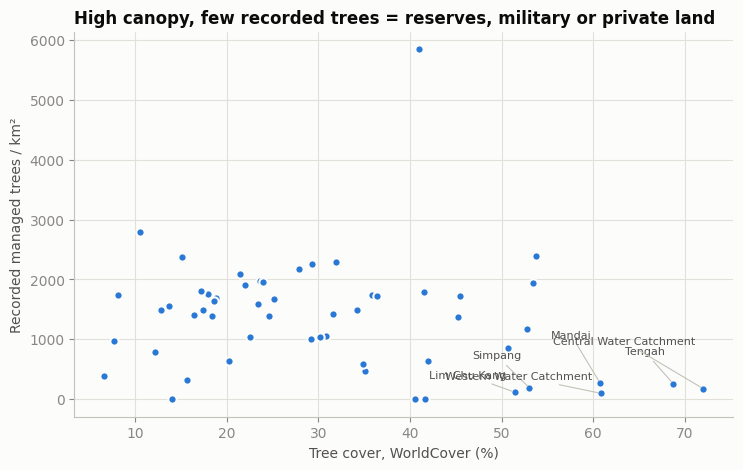

,planning_area,tree_pct,trees_per_km2,area_km2,reserve_share
8,CENTRAL WATER CATCHMENT,72.03,175.57,37.16,0.81
52,WESTERN WATER CATCHMENT,60.84,99.13,69.75,0.00
48,TENGAH,68.74,262.38,7.36,0.00
20,MANDAI,60.75,275.51,11.77,0.03
41,SIMPANG,53.05,189.54,8.28,0.00
19,LIM CHU KANG,51.42,118.55,17.50,0.07
26,NORTH-EASTERN ISLANDS,41.67,7.41,67.25,0.00
43,SOUTHERN ISLANDS,40.50,0.14,7.13,0.00
10,CHANGI BAY,50.74,850.65,1.97,0.00
22,MARINA SOUTH,42.00,645.25,1.63,0.00


In [ ]:
# Gap analysis: where land cover says "green" but the tree inventory is thin
if wc_ok:
    g = pa.copy()
    g["gap"] = g.tree_pct.rank(pct=True) - g.trees_per_km2.rank(pct=True)
    gaps = g.nlargest(10, "gap")[["planning_area", "tree_pct", "trees_per_km2", "area_km2"] +
                                 (["reserve_share"] if "reserve_share" in g else [])]
    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.scatter(g.tree_pct, g.trees_per_km2, s=36, color=C[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    lab = g.nlargest(6, "gap").sort_values("tree_pct")
    for k, (_, r) in enumerate(lab.iterrows()):
        ax.annotate(r.planning_area.title(), (r.tree_pct, r.trees_per_km2), xytext=(-6, 10 + 11 * (k % 3)),
                    textcoords="offset points", ha="right", fontsize=8, color=INK2,
                    arrowprops=dict(arrowstyle="-", color=BASE, lw=0.8))
    ax.set_xlabel("Tree cover, WorldCover (%)")
    ax.set_ylabel("Recorded managed trees / km²")
    ax.grid(axis="x")
    ax.set_title("High canopy, few recorded trees = reserves, military or private land")
    savefig(fig, "03d_gap_analysis")
    plt.show()
    display(gaps.round(2))
else:
    print("Gap analysis needs WorldCover; skipped.")

**Interpretation:** Areas with extensive satellite green cover and few recorded trees can reflect catchments, reserves, private greenery, inventory incompleteness or other land-use effects. The vegetation layers measure *standing vegetation*; they do not directly measure cuttings, maintenance frequency, or collectable annual residues. These spatial proxies must be calibrated with independent collection records before being reported as measured waste.

## 4 · Proxy allocation and sensitivity (not empirical waste validation)

Each planning area's national-share estimate is a weighted mixture of normalized managed-tree biomass, managed-tree count and managed green-area proxy. Because actual conversion from biomass stock to annual cutting generation is unknown, weights are **assumptions**. We draw 2,000 Dirichlet weight vectors and quantify how output shares change. These intervals are **sensitivity bands over weights**, **not** validated 90% prediction intervals. The median ranking correlation demonstrates internal stability only. Real validation requires municipal/operator measurements.

$$\hat{T}_z = T_{national} \sum_k w_k \frac{x_{z,k}}{\sum_j x_{j,k}},\qquad \sum_k w_k=1$$

In [ ]:
PROXIES = {"agb_t": "Biomass proxy (tree inventory)", "n_trees": "Managed tree count"}
if wc_ok:
    PROXIES["green_managed_km2" if reserves is not None else "green_km2"] = "Managed green area (land cover)"

T_NAT = float(horti.generated.loc[REFERENCE_YEAR])
X_df = pa[list(PROXIES)].fillna(0).copy()
# Land cover can't tell managed from unmanaged greenery. These areas are catchments, military
# or restricted islands: their greenery is real but mostly isn't pruned into the municipal
# waste stream. Their land-cover proxy is set to 0; their recorded managed trees still count.
UNMANAGED_AREAS = ["CENTRAL WATER CATCHMENT", "WESTERN WATER CATCHMENT", "NORTH-EASTERN ISLANDS", "WESTERN ISLANDS"]
lc_cols = [c for c in X_df if c in ("green_km2", "green_managed_km2")]
mask = pa.planning_area.isin(UNMANAGED_AREAS).to_numpy()
X_df.loc[mask, lc_cols] = 0
print(f"Land-cover proxy zeroed for {mask.sum()} planning areas: {sorted(pa.planning_area[mask])}")
X = X_df.to_numpy(float)
S = X / X.sum(axis=0)                                  # each proxy -> share of national total
w0 = np.full(len(PROXIES), 1 / len(PROXIES))

pa["share_baseline"] = S @ w0
pa["est_t_baseline"] = pa.share_baseline * T_NAT

rng = np.random.default_rng(SEED)
W = rng.dirichlet(np.ones(len(PROXIES)), size=N_WEIGHT_SAMPLES)
sims = (S @ W.T) * T_NAT                               # zones x samples
base_rank = stats.rankdata(-pa.est_t_baseline)
rank_rho = np.array([stats.spearmanr(pa.est_t_baseline, sims[:, k])[0] for k in range(N_WEIGHT_SAMPLES)])
top10 = (np.argsort(np.argsort(-sims, axis=0), axis=0) < 10).mean(axis=1)

pa["est_t_p05"], pa["est_t_p95"] = np.percentile(sims, 5, axis=1), np.percentile(sims, 95, axis=1)
pa["est_cv"] = sims.std(axis=1) / np.maximum(sims.mean(axis=1), 1e-9)
pa["p_top10"] = top10
print(f"Allocating {REFERENCE_YEAR} national total: {T_NAT:,.0f} t across {len(pa)} planning areas using {list(PROXIES.values())}")
print(f"Rank stability across {N_WEIGHT_SAMPLES} random weightings: median Spearman ρ = {np.median(rank_rho):.3f} "
      f"(5th pct {np.percentile(rank_rho, 5):.3f})")

Land-cover proxy zeroed for 4 planning areas: ['CENTRAL WATER CATCHMENT', 'NORTH-EASTERN ISLANDS', 'WESTERN ISLANDS', 'WESTERN WATER CATCHMENT']
Allocating 2025 national total: 232,000 t across 55 planning areas using ['Biomass proxy (tree inventory)', 'Managed tree count', 'Managed green area (land cover)']
Rank stability across 2000 random weightings: median Spearman ρ = 0.967 (5th pct 0.876)


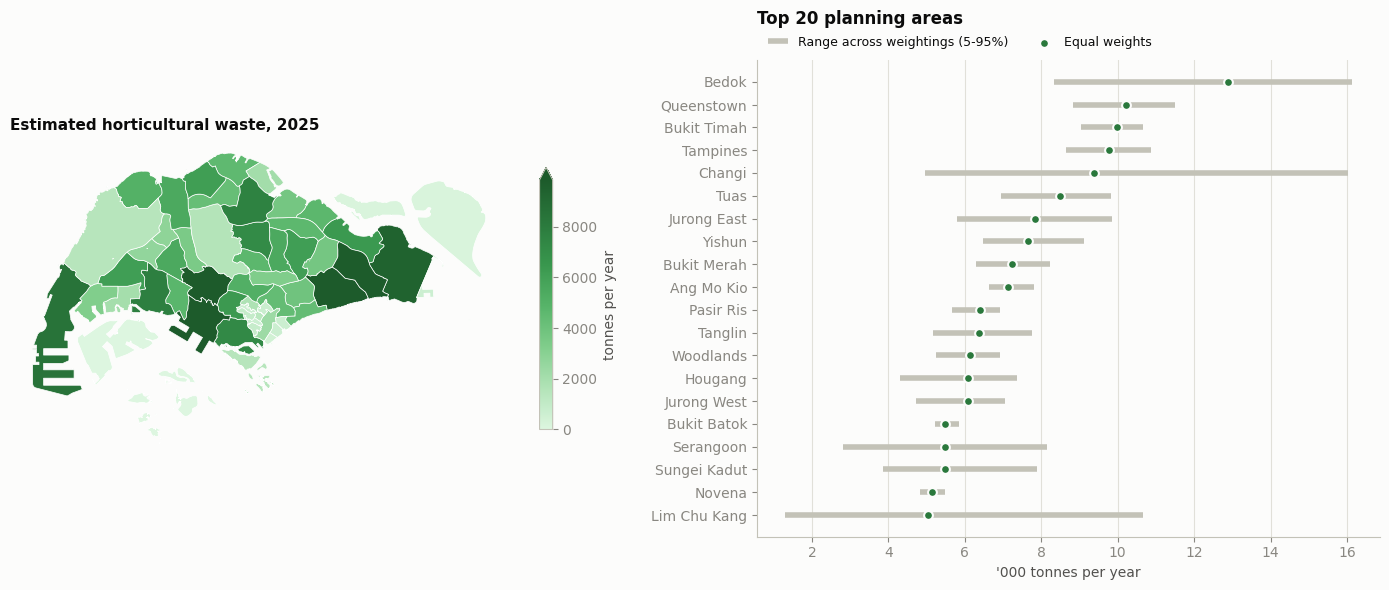

In [ ]:
fig = plt.figure(figsize=(14, 6))
ax_map = fig.add_subplot(1, 2, 1)
choropleth(ax_map, pa, "est_t_baseline", f"Estimated horticultural waste, {REFERENCE_YEAR}", "tonnes per year")
ax = fig.add_subplot(1, 2, 2)
top20 = pa.nlargest(20, "est_t_baseline").iloc[::-1]
y = np.arange(len(top20))
ax.hlines(y, top20.est_t_p05 / 1e3, top20.est_t_p95 / 1e3, color=BASE, lw=4, label="Range across weightings (5-95%)")
ax.scatter(top20.est_t_baseline / 1e3, y, color=GREEN_RAMP[5], s=40, zorder=3, edgecolor=SURFACE, linewidth=1.5, label="Equal weights")
ax.set_yticks(y, top20.planning_area.str.title())
ax.set_xlabel("'000 tonnes per year")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Top 20 planning areas", pad=26)
legend_above(ax, 2)
fig.tight_layout()
savefig(fig, "04a_waste_by_planning_area")
plt.show()

In [ ]:
# Haul distance (Derived): feedstock-weighted straight-line distance to ONE central plant at the
# feedstock-weighted centroid. Straight-line distance understates road distance, so treat it as a lower bound.
cent = pa.geometry.centroid
w = pa.est_t_baseline
site = (float((cent.x * w).sum() / w.sum()), float((cent.y * w).sum() / w.sum()))
dist_km = np.hypot(cent.x - site[0], cent.y - site[1]) / 1000
HAUL_KM = float((dist_km * w).sum() / w.sum())
site_area = pa.loc[pa.contains(gpd.points_from_xy([site[0]], [site[1]], crs=SVY21)[0]), "planning_area"]
print(f"Feedstock-weighted centre (a reference point for distance, not a proposed site) lies in "
      f"{site_area.iloc[0].title() if len(site_area) else 'n/a'}; mean straight-line haul to it: {HAUL_KM:.1f} km")
alloc_cols = ["planning_area", "region", "area_km2", "est_t_baseline", "est_t_p05", "est_t_p95", "est_cv", "p_top10"] + list(PROXIES)
pa["haul_km_to_central_site"] = dist_km
pa[alloc_cols + ["haul_km_to_central_site"]].sort_values("est_t_baseline", ascending=False).to_csv(PROC / "waste_by_planning_area.csv", index=False)
pa.to_file(PROC / "planning_area_features.gpkg", driver="GPKG")

Feedstock-weighted centre (a reference point for distance, not a proposed site) lies in Central Water Catchment; mean straight-line haul to it: 9.8 km


### 4a · Region-wise split

Planning-area estimates summed to URA's five regions. The 5–95% range comes from the same 2,000 random proxy weightings, summed within each region.

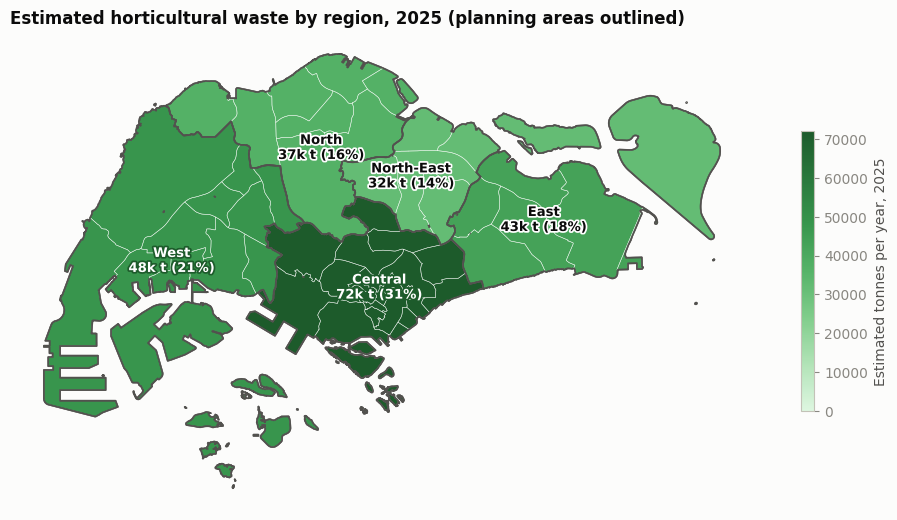

,planning_areas,area_km2,recorded_trees,est_t,est_t_p05,est_t_p95,share_pct,t_per_km2
region,,,,,,,,
Central,22,136.4,221685,72100.0,61000.0,81900.0,31.1,528.0
West,12,259.5,154243,48400.0,44500.0,51000.0,20.8,186.0
East,6,113.5,115923,42800.0,39600.0,47500.0,18.5,377.0
North,8,139.4,80424,36900.0,27500.0,50900.0,15.9,264.0
North-East,7,136.1,123637,31900.0,27500.0,38100.0,13.7,234.0


In [ ]:
idx = {r: (pa.region == r).to_numpy() for r in sorted(pa.region.dropna().unique())}
reg = pd.DataFrame({
    "planning_areas": {r: int(m.sum()) for r, m in idx.items()},
    "area_km2": {r: pa.area_km2[m].sum() for r, m in idx.items()},
    "recorded_trees": {r: pa.n_trees[m].sum() for r, m in idx.items()},
    "est_t": {r: pa.est_t_baseline[m].sum() for r, m in idx.items()},
    "est_t_p05": {r: np.percentile(sims[m].sum(axis=0), 5) for r, m in idx.items()},
    "est_t_p95": {r: np.percentile(sims[m].sum(axis=0), 95) for r, m in idx.items()},
}).rename_axis("region")
reg["share_pct"] = 100 * reg.est_t / reg.est_t.sum()
reg["t_per_km2"] = reg.est_t / reg.area_km2
reg = reg.sort_values("est_t", ascending=False)
reg.to_csv(PROC / "waste_by_region.csv")

import matplotlib.patheffects as pe
rg = regions.merge(reg, left_on="region", right_index=True)
fig, ax = plt.subplots(figsize=(12, 6.6))
vmax = rg.est_t.max()
rg.plot(column="est_t", ax=ax, cmap=SEQ, vmin=0, vmax=vmax, edgecolor=INK2, linewidth=1.2, legend=True,
        legend_kwds={"shrink": 0.55, "label": f"Estimated tonnes per year, {REFERENCE_YEAR}"})
pa.boundary.plot(ax=ax, color="white", linewidth=0.35, alpha=0.8)
rg.boundary.plot(ax=ax, color=INK2, linewidth=1.1)
for _, r in rg.iterrows():
    p = r.geometry.representative_point()
    dark = r.est_t > 0.6 * vmax
    ax.annotate(f"{r.region}\n{r.est_t / 1e3:,.0f}k t ({r.share_pct:.0f}%)", (p.x, p.y), ha="center", va="center",
                fontsize=9.5, fontweight="bold", color="white" if dark else INK,
                path_effects=[pe.withStroke(linewidth=2.5, foreground=GREEN_RAMP[6] if dark else "white")])
ax.set_axis_off()
ax.set_title(f"Estimated horticultural waste by region, {REFERENCE_YEAR} (planning areas outlined)", fontsize=12)
savefig(fig, "04b_waste_by_region_map")
plt.show()
(PROC / "eda_summary.json").write_text(json.dumps({
    "reference_year": REFERENCE_YEAR, "national_t": T_NAT, "haul_km": HAUL_KM,
    "planning_area_source": SOURCES.get("Planning areas"), "region_source": SOURCES.get("Regions")}, indent=1))
reg.round({"area_km2": 1, "est_t": -2, "est_t_p05": -2, "est_t_p95": -2, "share_pct": 1, "t_per_km2": 0})

## 5 · Exploratory Random Forest: managed-tree biomass proxy, not waste forecasts

The target variable is **log(1 + managed-tree biomass proxy in tonnes per approx. 230 m grid cell)**. Inputs are fractions of ESA WorldCover land-cover classes. The task does **not** estimate waste generated in tonnes/month and has no ground-truth regional waste quantities.

- **Validation scheme:** `GroupKFold(5)` split by URA planning area. Different cells from the same planning area do not appear in training and test simultaneously.
- **Baseline comparison:** mean-only, linear regression, random forest; report log-space R² and MAE.
- **Interpretation:** a positive grouped R² supports limited predictive skill for the chosen biomass target, not external transferability or operational forecasting. New cities require separate local training and validation.
- **If WorldCover cannot be downloaded:** model is not recomputed; earlier saved outputs are historical results, not refreshed measurements.

10,499 grid cells from 51 planning areas; 67% contain recorded trees


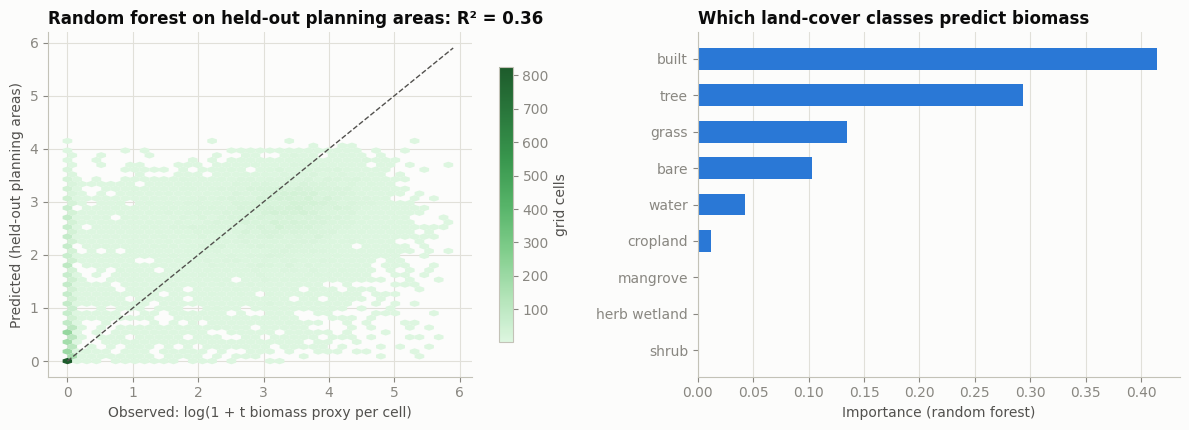

,R2 (log biomass),MAE (log biomass)
Mean (no skill),-0.032,1.544
Linear regression,0.232,1.207
Random forest,0.364,0.997


In [ ]:
if not wc_ok:
    print("WorldCover not available: baseline model skipped.")
else:
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import LinearRegression
    from sklearn.model_selection import GroupKFold, cross_val_predict
    from sklearn.metrics import r2_score, mean_absolute_error

    k = GRID_PIXELS
    H, Wd = (lc.shape[0] // k) * k, (lc.shape[1] // k) * k
    cell_id = ((np.arange(H)[:, None] // k) * (Wd // k)).astype(np.int32) + (np.arange(Wd)[None, :] // k).astype(np.int32)
    lc_c, zones_c, res_c = lc[:H, :Wd], zones[:H, :Wd], in_res[:H, :Wd]
    n_cells = (H // k) * (Wd // k)
    excluded = set(pa.index[pa.planning_area.isin(UNMANAGED_AREAS)] + 1)
    usable = (zones_c > 0) & ~res_c & ~np.isin(zones_c, list(excluded)) & (lc_c > 0)
    total = np.bincount(cell_id[usable], minlength=n_cells).astype(float)
    feats = {name: np.bincount(cell_id[usable & (lc_c == cls)], minlength=n_cells) / np.maximum(total, 1)
             for cls, name in WC_CLASSES.items()}
    zone_of_cell = np.zeros(n_cells, int)
    zone_of_cell[cell_id[usable]] = zones_c[usable]

    t4326 = tg.to_crs(wc_crs)
    inv = ~tr
    cols, rows_ = inv * (t4326.geometry.x.to_numpy(), t4326.geometry.y.to_numpy())
    rows_, cols = np.floor(rows_).astype(int), np.floor(cols).astype(int)
    ok = (rows_ >= 0) & (rows_ < H) & (cols >= 0) & (cols < Wd)
    tcell = cell_id[rows_[ok], cols[ok]]
    agb_cell = np.bincount(tcell, weights=t4326.agb_kg.to_numpy()[ok], minlength=n_cells) / 1000   # t per cell

    keep = total >= 0.5 * k * k                     # at least half the cell is usable land
    Xg = pd.DataFrame({n.replace("_", " "): v[keep] for n, v in feats.items()})
    Xg = Xg.loc[:, Xg.std() > 0]                    # drop classes absent from every cell
    yg = np.log1p(agb_cell[keep])
    groups = zone_of_cell[keep]
    print(f"{keep.sum():,} grid cells from {len(np.unique(groups))} planning areas; "
          f"{(agb_cell[keep] > 0).mean():.0%} contain recorded trees")

    cv = GroupKFold(n_splits=5)
    preds = {"Mean (no skill)": np.zeros_like(yg)}
    for tr_i, te_i in cv.split(Xg, yg, groups):
        preds["Mean (no skill)"][te_i] = yg[tr_i].mean()
    preds["Linear regression"] = cross_val_predict(LinearRegression(), Xg, yg, cv=cv, groups=groups)
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    preds["Random forest"] = cross_val_predict(rf, Xg, yg, cv=cv, groups=groups)
    scores = pd.DataFrame({m: {"R2 (log biomass)": r2_score(yg, p), "MAE (log biomass)": mean_absolute_error(yg, p)}
                           for m, p in preds.items()}).T
    scores.to_csv(PROC / "baseline_model_scores.csv")

    rf.fit(Xg, yg)
    imp = pd.Series(rf.feature_importances_, index=Xg.columns).sort_values()
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
    hb = a1.hexbin(yg, preds["Random forest"], gridsize=40, mincnt=1, cmap=SEQ, linewidths=0)
    lim = [0, max(yg.max(), preds["Random forest"].max())]
    a1.plot(lim, lim, color=INK2, lw=1, ls="--")
    a1.set_xlabel("Observed: log(1 + t biomass proxy per cell)")
    a1.set_ylabel("Predicted (held-out planning areas)")
    a1.set_title(f"Random forest on held-out planning areas: R² = {scores.loc['Random forest', 'R2 (log biomass)']:.2f}")
    fig.colorbar(hb, ax=a1, shrink=0.8, label="grid cells")
    a1.grid(axis="x")
    a2.barh(imp.index, imp.values, color=C[0], height=0.6)
    a2.set_xlabel("Importance (random forest)")
    a2.grid(axis="x"); a2.grid(axis="y", visible=False)
    a2.set_title("Which land-cover classes predict biomass")
    fig.tight_layout()
    savefig(fig, "05_baseline_model")
    plt.show()
    display(scores.round(3))

**Results scope:** For the original saved run, Random Forest R² = 0.364 and MAE = 0.997 in **log(1 + tonnes of managed-tree biomass proxy per cell)**; linear model R² = 0.232. The figure and metrics are **not** monthly horticultural waste predictions, yield forecasts, or validation outside Singapore. A deployment claim requires independent truth data and city-level external testing.

## 6 · Data quality, gaps and sources

In [ ]:
data_gaps = pd.DataFrame([
    ("Jumps in waste generated", ", ".join(map(str, [y for y in anomalies.index if y not in KNOWN])), "Not explained in NEA releases checked"),
    ("Monthly or regional waste data", "none published", "Only one national figure per year; regional figures in §4 are estimates"),
    ("Woody vs leafy split", "none published", "NEA reports horticultural waste as one total"),
    ("Fuel share by stream", "combined only", "NEA gives fuel tonnes for wood + horticultural together"),
    ("Tree inventory vintage", "Oct 2021 copy", "NParks' live database is larger; 'age' field undocumented, not used"),
    ("Land cover year", "2021", "Single year; cannot separate managed from unmanaged greenery beyond the reserve mask"),
    ("Girth class L midpoint", f"{GIRTH_MIDPOINT_M['L']} m", "Assumption: top class is open-ended (>1.5 m)"),
    ("Proxy weights (§4)", "equal", "Assumption: tested with 2,000 random weightings"),
], columns=["item", "status", "note"]).set_index("item")
data_gaps.to_csv(PROC / "data_gaps.csv")
print("DATA SOURCES USED IN THIS RUN")
for k, v in SOURCES.items():
    print(f"  - {k}: {v}")
print("\nDATA-QUALITY NOTES")
for n in NOTES:
    print(f"  - {n}")
data_gaps

DATA SOURCES USED IN THIS RUN
  - National waste series: data.gov.sg API (live)
  - Fuel tonnage: NEA Waste and Recycling Statistics 2015-2025, footnotes (wood + horticultural combined)
  - Weather: MSS daily records, stations ['Changi']
  - Planning areas: URA Master Plan 2019 subzones (data.gov.sg), dissolved
  - Nature reserves: NParks Nature Reserves Gazette (data.gov.sg)
  - Regions: URA Master Plan 2019 subzones (REGION_N), dissolved
  - Managed trees: NParks Trees.sg via GitHub cheeaun/sgtreesdata (© NParks)
  - Land cover: ESA WorldCover 2021 v200 (10 m)

DATA-QUALITY NOTES
  - MSS: 4 station-months could not be downloaded.
  - Weather years dropped for <80% daily coverage: [2026]
  - Trees: 0.24% missing girth and 0.17% missing height imputed (median / median-by-girth).
  - Trees: 0.05% of points fall outside planning-area polygons (coast/offshore) and are excluded.


,status,note
item,,
Jumps in waste generated,"2001, 2002, 2018",Not explained in NEA releases checked
Monthly or regional waste data,none published,Only one national figure per year; regional fi...
Woody vs leafy split,none published,NEA reports horticultural waste as one total
Fuel share by stream,combined only,NEA gives fuel tonnes for wood + horticultural...
Tree inventory vintage,Oct 2021 copy,NParks' live database is larger; 'age' field u...
Land cover year,2021,Single year; cannot separate managed from unma...
Girth class L midpoint,1.9 m,Assumption: top class is open-ended (>1.5 m)
Proxy weights (§4),equal,"Assumption: tested with 2,000 random weightings"


## 7 · Interim feedback resolution and validation gate

**Reviewer action log**

1. **Scope:** Singapore only; pyrolysis/biochar only. Other technology pathways and global rollout are future work.
2. **Feedstock:** all planning area tonnages are spatial allocations of a national total using **stock proxies**. Do not call them measured regional waste. Independent collection data needed.
3. **Uncertainty:** 2,000 weights provide **internal weight sensitivity** and ranking stability, not model accuracy or 90% calibrated prediction intervals.
4. **AI target:** R² = 0.364 pertains to **log biomass proxy** under held-out planning area groups, not monthly waste forecasting.
5. **Weather:** no consistent annual association; do **not** infer maintenance schedules as the true cause without maintenance records.
6. **Carbon:** separate *gross stored CO₂*, *net effect versus existing treatment*, *hypothetical registry credits*; never infer credits from stored carbon or Singapore carbon tax.
7. **Implementation:** current notebook = EDA; Streamlit demonstrator = deterministic scenario screening and small-set enumeration. True road distances, NSGA-II and registry dMRV **not completed**.
8. **Compelling demonstration:** users select illustrative map anchors and compare one vs multiple processing hubs under equal throughput. Geographical feasibility remains unverified.

**Validation protocol:** secure 2025 operator or town council region-level collection totals with documented geographical definitions; compare national reconciliation, coverage, weighted absolute percentage error, and Spearman ranking; identify regional bias. Until such records are available, **independent validation remains pending**.

**Implementation note:** a separate `BioTwin_Prototype` package contains the functioning Streamlit app, transparent calculation core, six automated tests, an empty real-data validation template, and a provenance register. Actual operators and permitted land sites must replace illustrative defaults before use as planning advice.

In [ ]:
# Export spatial EDA results in the precise schema accepted by the separate Streamlit app.
# This cell runs only AFTER the source data and spatial allocations above are recomputed.
# It does not alter the original processed data or imply any external validation.

from pathlib import Path
import json

app_export = ROOT / "biotwin_app_export"
app_export.mkdir(exist_ok=True, parents=True)

# Projected EPSG:3414 centroid positions are converted to WGS84 for map display.
# They are estimated supply origin centroids, not actual cutting or pickup points.
pa_cent = gpd.GeoSeries(pa.geometry.centroid, crs=pa.crs).to_crs("EPSG:4326")
area_table = pd.DataFrame({
    "planning_area": pa.planning_area.to_numpy(),
    "region": pa.region.to_numpy(),
    "estimated_t": pa.est_t_baseline.to_numpy(),
    "p05_t": pa.est_t_p05.to_numpy(),
    "p95_t": pa.est_t_p95.to_numpy(),
    "latitude": pa_cent.y.to_numpy(),
    "longitude": pa_cent.x.to_numpy(),
    "estimate_status": "2025 regional total allocated from proxies; not observed 2025 waste",
})
area_table.to_csv(app_export / "planning_area_estimates.csv", index=False)
print(f"Exported {len(area_table)} planning areas; mass balance: "
      f"{area_table.estimated_t.sum():,.1f} vs NEA {T_NAT:,.1f} tonnes")
assert len(area_table) == 55, "Expected 55 planning areas: review URA source and boundaries"
assert abs(area_table.estimated_t.sum()-T_NAT) < 1e-5

# Independent validation: intentionally BLANK. Must NOT copy predicted estimates as observations.
validation = pd.DataFrame({"region": sorted(reg.region.unique()), "year": 2025,
                           "observed_t": float("nan"), "source": "",
                           "record_type": "operator collection / collection depot records",
                           "notes": "requires independent 2025 regional measurement"})
validation.to_csv(app_export / "operator_validation_TEMPLATE.csv", index=False)

(reg.drop(columns=["t_per_km2"],errors="ignore").reset_index()).to_csv(
    app_export / "region_allocation_raw_from_notebook.csv", index=False)

metadata = {
    "year": REFERENCE_YEAR, "country": "Singapore",
    "technology": "pyrolysis to biochar (illustrative downstream module)",
    "national_t": T_NAT, "weight_samples": N_WEIGHT_SAMPLES,
    "median_rank_spearman": float(np.median(rank_rho)),
    "allocation_validation": "PENDING independent operator data",
    "machine_learning_target": "log(1 + managed-tree biomass proxy per grid cell)",
    "machine_learning_not_monthly_waste": True,
    "data_sources": SOURCES,
    "export_type": "derived proxy estimates, not observations",
}
(app_export / "analysis_provenance.json").write_text(json.dumps(metadata, indent=2))
print("Export folder:", app_export)
print("Copy planning_area_estimates.csv to BioTwin_Prototype/data/ to enable 55-area origin routing.")

In [ ]:
import zipfile
archive = ROOT / "eda_outputs.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (FIG, PROC):
        for f in sorted(folder.rglob("*")):
            if f.is_file():
                z.write(f, f.relative_to(ROOT))
print(f"Packed {archive.stat().st_size / 1e6:.1f} MB of figures and processed data into {archive}")
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))